In [9]:
from sklearn.datasets import load_wine
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import TruncatedSVD
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

In [3]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

In [4]:

print(f"Розміри матриці ознак (рядки, стовпці): {X.shape}")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Розміри матриці ознак (рядки, стовпці): (178, 13)


In [6]:
# 2
svd = TruncatedSVD(n_components=2, random_state=42)
X_svd = svd.fit_transform(X_scaled)

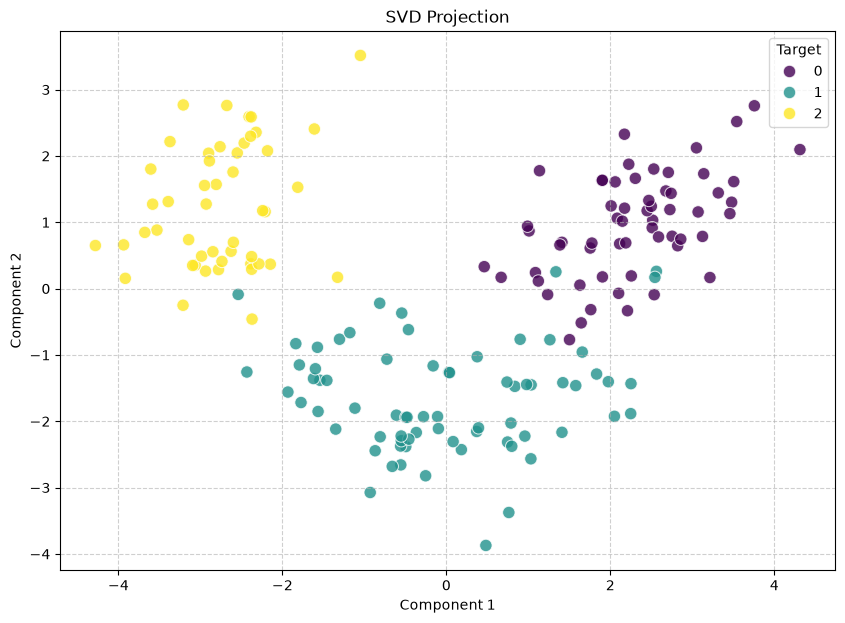

In [7]:
plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_svd[:, 0], y=X_svd[:, 1], hue=y, palette='viridis', s=80, alpha=0.8)
plt.title('SVD Projection')
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.legend(title='Target')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [10]:
# Завдання 3

pca = PCA(n_components=2, random_state=42)

# (X_scaled беремо з Завдання 1)
X_pca = pca.fit_transform(X_scaled)

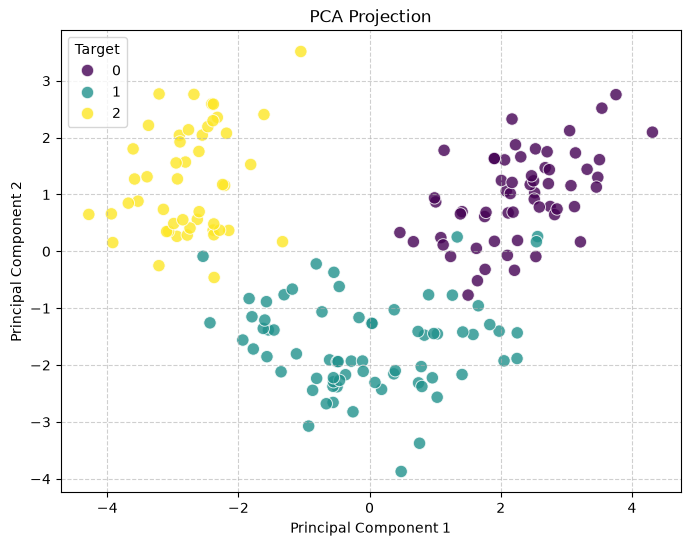

In [11]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette='viridis', s=80, alpha=0.8)
plt.title('PCA Projection')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Target')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Частка поясненої дисперсії (PCA): [0.36198848 0.1920749 ]
Загальна пояснена дисперсія 2 компонентами: 55.41%


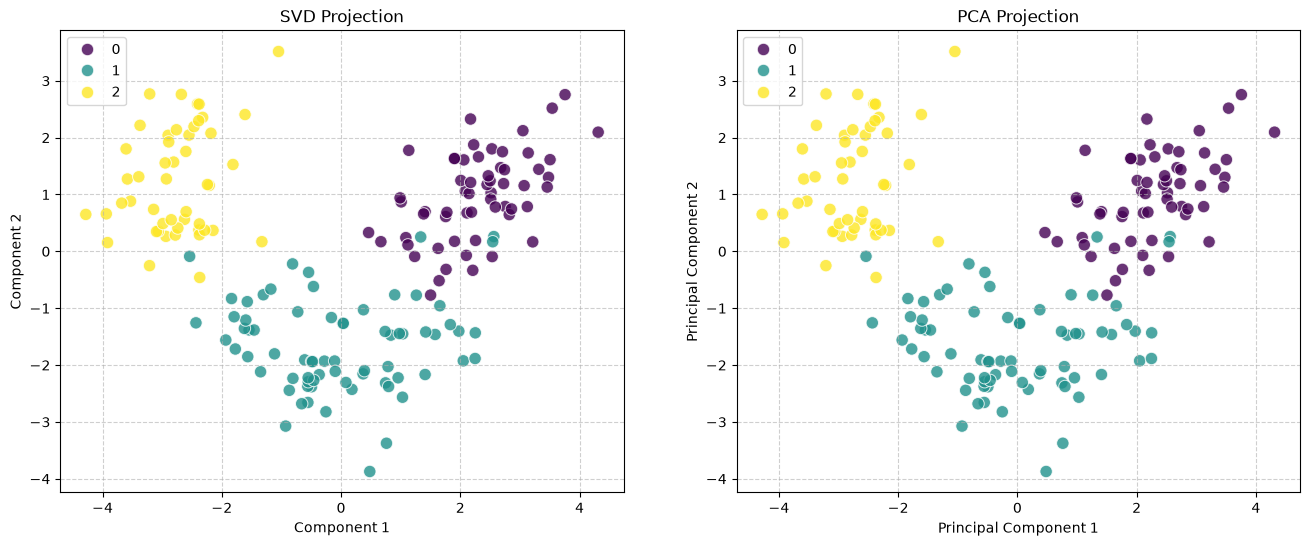

In [ ]:
# Завдання 4

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Графік SVD (ліворуч)
sns.scatterplot(
    x=X_svd[:, 0], y=X_svd[:, 1], hue=y, 
    palette='viridis', s=80, alpha=0.8, ax=axes[0]
)
axes[0].set_title('SVD Projection')
axes[0].set_xlabel('Component 1')
axes[0].set_ylabel('Component 2')
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Графік PCA (праворуч)
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1], hue=y, 
    palette='viridis', s=80, alpha=0.8, ax=axes[1]
)
axes[1].set_title('PCA Projection')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
axes[1].grid(True, linestyle='--', alpha=0.6)

# Виведення частки поясненої дисперсії для PCA
explained_variance = pca.explained_variance_ratio_
print(f"Частка поясненої дисперсії (PCA): {explained_variance}")
print(f"Загальна пояснена дисперсія 2 компонентами: {sum(explained_variance) * 100:.2f}%")

# Збереження зображення у файл
plt.savefig('dimensionality_reduction_comparison.png', dpi=300, bbox_inches='tight')

plt.show()